The analysis use simulated raman data since I dont know where to get the raw data.
The setup is 12 donors, 3 skin pieces per donor and 1 Raman spectra per piece. Each piece has a hidden lipid order, where ordered lipids give a tighter barrier and therefore lower flux. 
One IVPT flux value is attached to each piece.

In [1]:
# packages, ran by Gcolab

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path # OOP? Cross plaTFORM

# to optimize the process
from scipy import sparse # sparse matrices/arrays. stores only non-zero values
from sklearn.preprocessing import StandardScaler # preprocessing, standarizes feature

# for PCA analysis
from sklearn.decomposition import PCA
from scipy.stats import spearmanr  # rank correlation: robust, does not assume a straight line
from scipy.signal import find_peaks # raman peak

# for PLS analysis
from scipy.sparse.linalg import spsolve
from scipy.signal import savgol_filter, medfilt # remove outliers
from scipy.stats import pearsonr # check linear correlation between variables
from sklearn.cross_decomposition import PLSRegression # find latent component
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict, LeaveOneGroupOut # cross validation
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# out path to gdrive

# 1 -- raw data generation set up
simulate raman spectra, input some tissue biophysical value

In [2]:
SEED = 67 # random generator
RNG = np.random.default_rng(SEED) # fixed seed -> same "random" data every run (reproducible)
OUT = Path("guideskin_out"); OUT.mkdir(exist_ok=True)

In [3]:
# functions helper -- general

# save output
def save(name):
    plt.tight_layout(); plt.savefig(OUT / f"{name}.png", dpi=130); plt.close()

# show plot
def show(name):
    """Save the current figure to disk AND display it. Called at the end of every step."""
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=120)
    plt.show()

In [4]:
# function helper - raman data generation

# gaussian dist
def gauss(centre, width, height=1.0):
    return height * np.exp(-0.5 * ((wn - centre) / width) ** 2)

# clean spectrum
def clean_spectrum(order, water, lipid_scale):
    """Noise-free spectrum. order 0-1 (1 = tight trans chains), water 0-1, lipid_scale ~1 (more sebum -> bigger lipid bands)."""
    s = np.zeros_like(wn)
    for band in BANDS:
        centre, sigma, h0, k_order, k_water = band[:5] # ignore label / source fields
        height = h0 + k_order * order + k_water * water
        if centre == 1080: # gauche band rises as order falls
            height = h0 + 0.50 * (1 - order)
        if centre in LIPID:
            height *= lipid_scale
        if centre == 2850: # band moves instead of changing height
            centre = 2854.0 - 4.0 * order # ordered -> lower wavenumber
        s += gauss(centre, sigma, height)
    return s

# measured spectrum with noise
def measured_spectrum(clean):
    """Add what an instrument adds: fluorescence background, random intensity, noise, cosmic-ray spikes."""
    x = (wn - wn.min()) / (wn.max() - wn.min()) # normalise axis
    fluo = (RNG.uniform(1, 3) + RNG.uniform(-1, 1) * x + RNG.uniform(-1, 1) * x ** 2
            + RNG.uniform(.5, 1.5) * np.exp(-0.5 * ((x - RNG.uniform(.2, .6)) / .25) ** 2)) # flat, straight, curvy slope
    s = RNG.uniform(.7, 1.3) * clean + fluo + RNG.normal(0, .1, wn.size) # integrate
    if RNG.random() < .15:  # 1-2 cosmic-ray spikes
        for _ in range(RNG.integers(1, 3)): s[RNG.integers(5, wn.size - 5)] += RNG.uniform(2, 5)
    return s

In [5]:
# defining samples

N_DONORS, N_REP = 30, 3
SITES  = ["body", "arm", "leg"]
GROUPS       = ["invivo_healthy", "exvivo_healthy", "exvivo_burnt", "invivo_wounded"]
TRAIN_GROUPS = ["invivo_healthy", "exvivo_healthy", "exvivo_burnt"]  
TEST_GROUP   = "invivo_wounded"                                      
HEALTHY      = ["invivo_healthy", "exvivo_healthy"]                   
COL = {"invivo_healthy": "#2a9d8f", "exvivo_healthy": "#264653", "exvivo_burnt": "#9b2226", "invivo_wounded": "#e76f51"}

In [6]:
# defining sample value

SITE = {
    "body": dict(hyd=29.0, seb=60.0, tewl=9.0,  flux=1.00),
    "arm":  dict(hyd=34.0, seb=12.0, tewl=12.0,  flux=0.62),
    "leg":  dict(hyd=32.0, seb=10.0, tewl=15.0, flux=0.82),
}
# Healthy in vivo mean per body site.
#  tewl : g/m2/h. An evaluation of mechanical and biophysical skin parameters at different body locations, 10.1111/srt.13292 (assumed value)
#  hyd  : Corneometer-like AU (0-100). An evaluation of mechanical and biophysical skin parameters at different body locations, 10.1111/srt.13292 (assumed value)
#  seb  : Sebumeter ug/cm2, order of magnitude only (assumed value)
#  flux : relative IVPT permeation, body = 1 (notebook ratios, benzoic acid) (assumed value)


# Group modifiers, multiplied onto the healthy in vivo site mean.
GROUP = {  #   hyd   seb   tewl  lipid order  flux(ex vivo)  hidden breach
    "invivo_healthy": dict(hyd=1.00, seb=1.00, tewl=1.00, order=0.60, flux=1.00, breach=0.0),
    "exvivo_healthy": dict(hyd=0.85, seb=0.60, tewl=1.30, order=0.57, flux=0.70, breach=0.0),
    "exvivo_burnt":   dict(hyd=0.45, seb=0.40, tewl=2.25, order=0.15, flux=1.50, breach=1.5),
    "invivo_wounded": dict(hyd=1.30, seb=0.60, tewl=2.00, order=0.38, flux=1.35, breach=1.0),
}

# F0 ~ caffeine-like 1% aqueous: Kp 5e-4..1e-3 cm/h x 10 mg/mL = ~5-10 ug/cm2/h on trunk [ASSUMED].
F0 = 7.0
B_ORDER, B_HYD, B_TEWL, B_SEB, B_BREACH = -2.0, 0.010, 0.40, -0.10, 0.20
SD = dict(
    donor_order=0.06, donor_hyd=8.0, donor_seb=0.40, donor_tewl=0.25, donor_flux=0.25, # people
    piece_order=0.04, piece_hyd=4.0, piece_seb=0.15, piece_tewl=0.10, flux_noise=0.20, # pieces
    rep_order=0.03,   rep_hyd=3.0,   rep_seb=0.08,   rep_tewl=0.15,  # replicates
    # Raman reads a slightly different spot (and depth) than the Corneometer, so its water / lipid signal agrees only partly. 
    spot_hyd=6.0, spot_seb=0.15
    )


In [7]:
# defining raman reference data
wn = np.arange(600, 3702, 2.0)  # Raman shift in cm-1, 1551 points

# the base raman spectra data of human skin (general)
# data from Novel aspects of Raman spectroscopy in skin research (Lunter, D. et. al., 2022) >> DOI 10.1111/exd.14645
# centre, sigma, base height, k_order, k_hydration, label, source
BANDS = [
    (1003,   4, 0.20,  0.00, 0.00, "Phe ring (protein)",                    "gen"),
    (1060,   6, 0.30,  0.45, 0.00, "v(C-C) trans  -> ordered lipid",        "Li20"),
    (1080,  14, 0.15, -0.50, 0.00, "v(C-C) gauche -> disordered lipid",     "Li20"),  # -0.5*O + 0.5 below
    (1130,   6, 0.30,  0.45, 0.00, "v(C-C) trans  -> ordered lipid",        "Li20"),
    (1274,  10, 0.35,  0.00, 0.00, "amide III, alpha-helix",                "Lu22"),
    (1296,   8, 0.55,  0.00, 0.00, "delta(CH2) lipid",                      "Lu22"),
    (1421,   8, 0.25,  0.00, 0.00, "delta(CH3)",                            "Lu22"),
    (1440,  12, 0.85,  0.00, 0.00, "CH2 scissoring lipid+protein",          "gen"),
    (1552,  10, 0.20,  0.00, 0.00, "amide II",                              "Lu22"),
    (1652,  14, 0.90,  0.00, 0.00, "amide I, alpha-helix (keratin)",        "Lu22"),
    (1743,   8, 0.12,  0.00, 0.00, "C=O ester (lipid)",                     "Lu22"),
    (2850,   9, 1.00,  0.00, 0.00, "vs(CH2)  [position shifts, see below]", "Li20"),
    (2880,  10, 0.55,  0.80, 0.00, "vas(CH2) [lateral packing]",            "Li20"),
    (2935,  14, 0.90,  0.00, 0.00, "CH3 / protein",                         "gen"),
    (3450, 100, 0.30,  0.00, 1.20, "OH stretch of water (broad)",           "Ca01"),
]
LIPID = {1296, 1440, 1743, 2850, 2880} # bands that should grow with sebum (?)

In [8]:
sig_pos = RNG.uniform(700, 1700, 6) # donor fingerprint: small peaks unique to each person
rows, spectra = [], []

for d in range(N_DONORS):
    donor = f"D{d+1:02d}"
    dn = dict(order=RNG.normal(0, SD["donor_order"]), hyd=RNG.normal(0, SD["donor_hyd"]), seb=RNG.normal(0, SD["donor_seb"]), tewl=RNG.normal(0, SD["donor_tewl"]), flux=RNG.normal(0, SD["donor_flux"]))
    fingerprint = sum(gauss(p, 10, .06 * c) for p, c in zip(sig_pos, RNG.normal(0, 1, 6)))
    for g in GROUPS:
        G = GROUP[g]
        for site in SITES:
            S = SITE[site]
            # hidden true state of this skin piece
            O  = np.clip(G["order"] + dn["order"] + RNG.normal(0, SD["piece_order"]), .05, .95)
            H  = np.clip(S["hyd"] * G["hyd"] + dn["hyd"] + RNG.normal(0, SD["piece_hyd"]), 5, 100)
            SB = np.clip(S["seb"] * G["seb"] * np.exp(dn["seb"] + RNG.normal(0, SD["piece_seb"])), 5, 300)
            TW = np.clip(S["tewl"] * G["tewl"] * np.exp(dn["tewl"] + RNG.normal(0, SD["piece_tewl"])), 2, 80)
            ln_f = (np.log(F0) + np.log(S["flux"]) + np.log(G["flux"]) + dn["flux"] + B_ORDER * (O - .6)
                    + B_HYD * (H - S["hyd"]) + B_TEWL * np.log(TW / S["tewl"]) + B_SEB * np.log(SB / S["seb"])
                    + B_BREACH * G["breach"] + RNG.normal(0, SD["flux_noise"]))
            flux = float(np.clip(np.exp(ln_f), .1, 60))
            # replicate readings of the same spot: spectrum + hydration + sebum + TEWL
            for r in range(N_REP):
                H_r  = float(np.clip(H + RNG.normal(0, SD["rep_hyd"]), 5, 100))
                SB_r = float(np.clip(SB * np.exp(RNG.normal(0, SD["rep_seb"])), 5, 300))
                TW_r = float(np.clip(TW * np.exp(RNG.normal(0, SD["rep_tewl"])), 2, 80))
                H_sp, SB_sp = np.clip(H + RNG.normal(0, SD["spot_hyd"]), 5, 100), SB * np.exp(RNG.normal(0, SD["spot_seb"]))   # what Raman sees
                lipid_scale = float(np.clip(1 + .2 * np.log(SB_sp / S["seb"]), .6, 1.4))
                O_r = np.clip(O + RNG.normal(0, SD["rep_order"]), 0, 1)
                spectra.append(measured_spectrum(clean_spectrum(O_r, (H_sp - 5) / 95, lipid_scale) + fingerprint))
                rows.append(dict(donor=donor, site=site, group=g, piece=f"{donor}_{site}_{g}", replicate=r + 1,
                                 hydration=H_r, sebum=SB_r, tewl=TW_r, flux=flux, true_order=O_r,
                                 true_hyd=H, true_seb=SB, true_tewl=TW))   # truth, kept ONLY for diagnostics (section 11)

meta = pd.DataFrame(rows) # one row per replicate measurement (the "metadata" table)
X_raw = np.array(spectra) # shape (432, 1551): one raw spectrum per row of meta
assert len(meta) == len(X_raw) == N_DONORS * len(SITES) * len(GROUPS) * N_REP     # 12 x 3 x 4 x 3 = 432
print("simulated rows:", len(meta), "| spectra:", X_raw.shape)


simulated rows: 1080 | spectra: (1080, 1551)


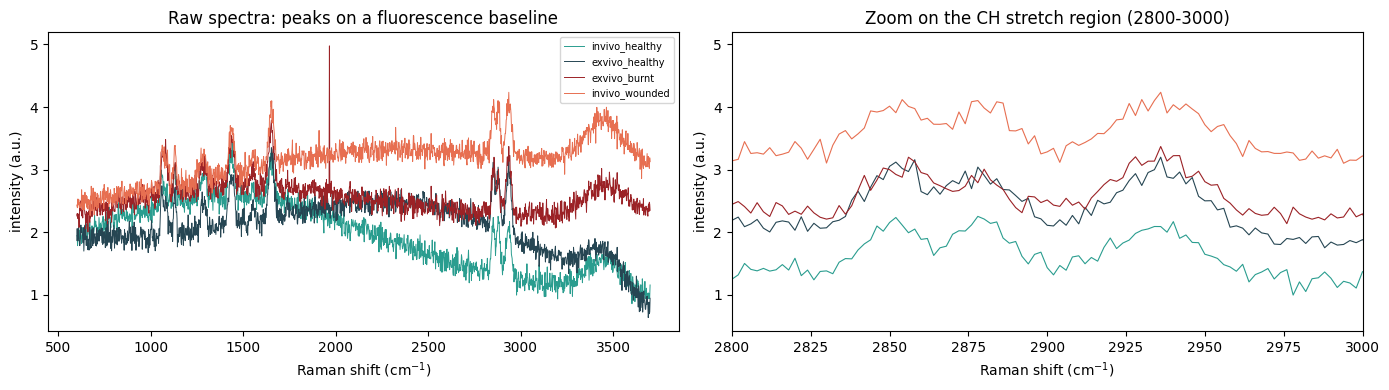

In [9]:
# plot raman spectra

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for g in GROUPS:
    i = np.where(meta.group == g)[0][0]  # first spectrum of each group
    ax[0].plot(wn, X_raw[i], lw=.7, c=COL[g], label=g)
    ax[1].plot(wn, X_raw[i], lw=.8, c=COL[g])

ax[0].set_title("Raw spectra: peaks on a fluorescence baseline")
ax[0].legend(fontsize=7)

ax[1].set_xlim(2800, 3000)
ax[1].set_title("Zoom on the CH stretch region (2800-3000)")

for a in ax: a.set_xlabel("Raman shift (cm$^{-1}$)"); a.set_ylabel("intensity (a.u.)")
show("fig01_raw_spectra")


                    hydration        sebum          tewl          flux       
                         mean   std   mean    std   mean    std   mean    std
group          site                                                          
exvivo_burnt   arm      18.23  6.52   5.65   1.08  28.45   8.58  27.82  11.15
               body     15.13  7.94  23.95   9.90  22.07   7.77  43.04  11.64
               leg      16.01  7.22   5.43   0.64  37.41  11.24  34.58  11.49
exvivo_healthy arm      31.14  8.42   8.09   3.09  16.69   5.59   3.57   1.17
               body     25.37  7.39  36.38  15.94  12.99   3.67   6.17   2.54
               leg      27.84  9.96   6.60   1.97  21.15   6.21   4.89   1.89
invivo_healthy arm      35.96  8.62  12.30   4.78  12.90   4.38   4.46   1.76
               body     29.56  8.75  61.34  25.17   9.23   3.01   6.62   2.57
               leg      33.54  7.95  10.44   4.16  16.64   4.62   5.73   1.51
invivo_wounded arm      47.32  8.03   7.58   2.25  25.00   7.35 

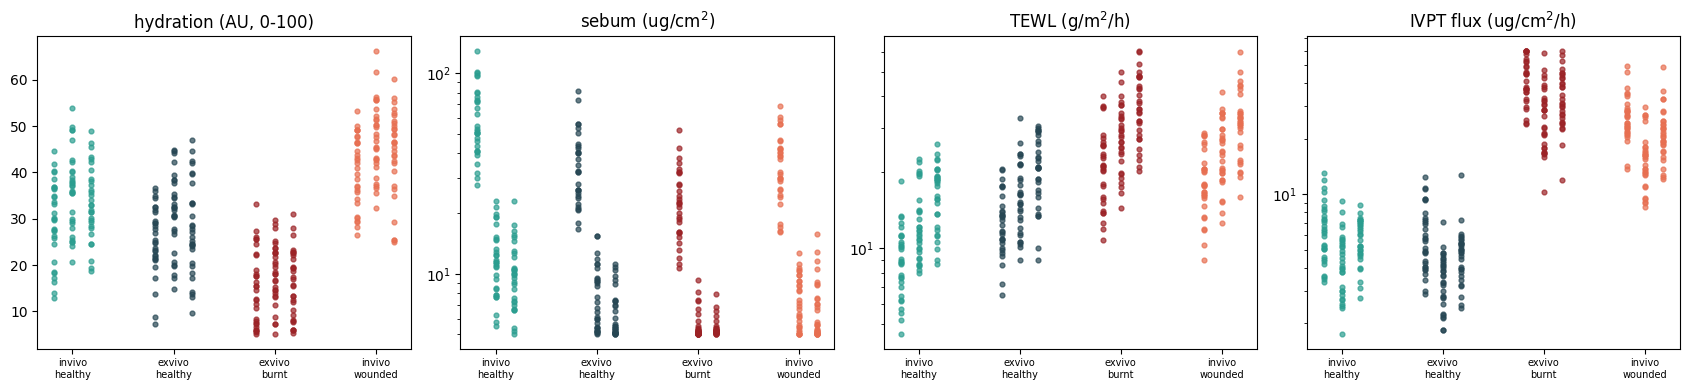

In [10]:
# plot simulated biophysical properties (averaged)

piece_tbl = (meta.groupby(["group", "site", "piece"], as_index=False)
                 .agg(hydration=("hydration", "mean"), sebum=("sebum", "mean"),
                      tewl=("tewl", "mean"), flux=("flux", "first"))) 

summary = (piece_tbl.groupby(["group", "site"])[["hydration", "sebum", "tewl", "flux"]]
                    .agg(["mean", "std"]).round(2)) # summary all pieces
# summary.to_csv(OUT / "01_simulated_summary_by_group_site.csv")
print(summary.to_string())  

print("\nflux by group (ug/cm2/h), geometric mean [min-max]:")
for g in GROUPS:
    d = piece_tbl[piece_tbl.group == g]
    print(f"  {g:15s} {np.exp(np.log(d.flux).mean()):6.2f}  [{d.flux.min():.2f}-{d.flux.max():.2f}]")

assert meta[["hydration", "sebum", "tewl", "flux"]].notna().all().all() # no missing
assert meta.hydration.between(5, 100).all() and meta.sebum.between(5, 300).all() # in scale

# scatter graph
fig, ax = plt.subplots(1, 4, figsize=(17, 4))

# var = type to plot, lab = title, logy = LogY axis/not
for a, (var, lab, logy) in zip(ax, [("hydration", "hydration (AU, 0-100)", False),
                                    ("sebum", "sebum (ug/cm$^2$)", True),
                                    ("tewl", "TEWL (g/m$^2$/h)", True),
                                    ("flux", "IVPT flux (ug/cm$^2$/h)", True)]):
    for gi, g in enumerate(GROUPS):
        for si, s in enumerate(SITES):
            d = piece_tbl[(piece_tbl.group == g) & (piece_tbl.site == s)] # body, arm, leg
            a.scatter(np.full(len(d), gi) + (si - 1) * 0.18, d[var], c=COL[g], s=12, alpha=0.7)
    a.set_xticks(range(4))
    a.set_xticklabels([g.replace("_", "\n") for g in GROUPS], fontsize=7)
    a.set_title(lab)
    if logy: a.set_yscale("log")
show("fig02_simulated_biophysics_flux")

# 2 -- preprocessing

In [11]:
# functions helper -- preprocessing

_L = wn.size
_D = sparse.diags([1.0, -2.0, 1.0], [0, -1, -2], shape=(_L, _L - 2))   # second-difference operator
_PEN = 1e5 * _D.dot(_D.T) # smoothness penalty; 1e5 = baseline stiffness (lambda).

def despike(y, window=5, n_mad=8):
    """Cosmic rays are 1-2 points wide. A median filter ignores them, so the
    difference (y - median) is large only at spikes."""
    med = medfilt(y, window); res = y - med
    mad = np.median(np.abs(res - np.median(res))) * 1.4826  # robust sigma from the Median Absolute Deviation
    bad = np.abs(res) > n_mad * mad  # more than 8 robust sigmas from the median = spike
    y2 = y.copy(); y2[bad] = med[bad]
    return y2
    

def asls_baseline(y, lam=1e5, p=0.01, n_iter=10):
    """Asymmetric least squares (Eilers & Boelens 2005).
    Fits a very smooth curve z under the spectrum. Points ABOVE the curve
    (peaks) get a tiny weight p, points below get weight 1-p, so the curve
    hugs the bottom of the spectrum instead of cutting through the peaks.
      lam : smoothness (bigger = stiffer baseline)
      p   : asymmetry (smaller = baseline stays lower)"""
    L = y.size
    D = sparse.diags([1.0, -2.0, 1.0], [0, -1, -2], shape=(L, L - 2))
    penalty = lam * D.dot(D.T)                  # penalises curvature
    w = np.ones(L)
    for _ in range(n_iter):
        W = sparse.spdiags(w, 0, L, L)
        z = spsolve((W + penalty).tocsc(), w * y)
        w = p * (y > z) + (1 - p) * (y < z)
    return z

def preprocess(y):
    y = despike(y)
    y = savgol_filter(y, window_length=9, polyorder=3)   # noise reduction
    y = y - asls_baseline(y)                             # remove fluorescence
    y = y / np.linalg.norm(y)                            # vector normalisation
    return y

X = np.array([preprocess(s) for s in X_raw])  # preprocessed spectra, same shape as X_raw

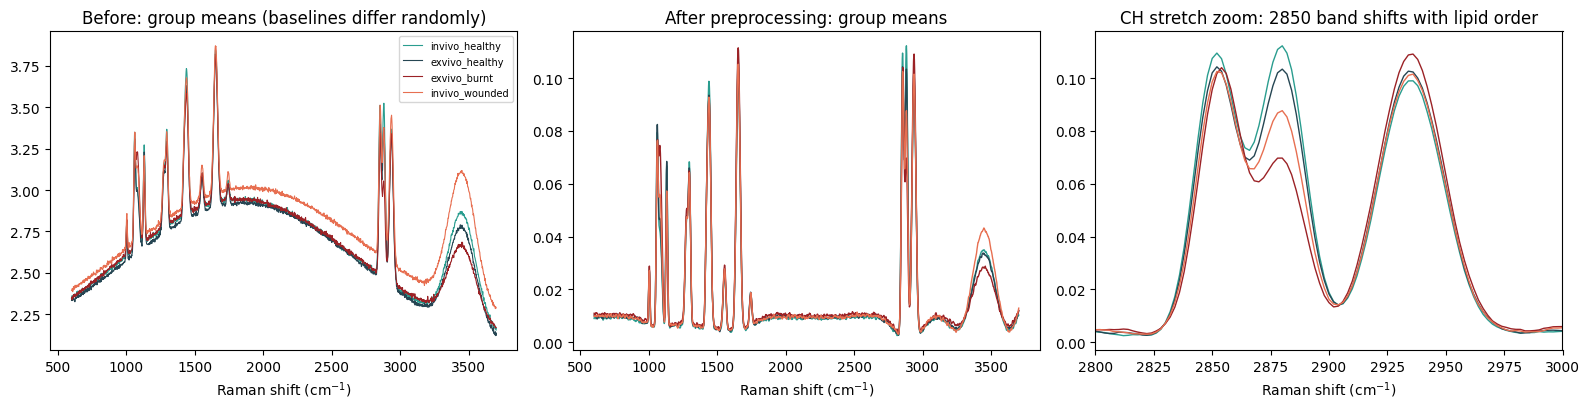

In [ ]:
# raman preprocessing
spike_size = [np.abs(s - despike(s)).max() for s in X_raw[:60]]
i = int(np.argmax(spike_size)) # choose one clearest despike
y0 = X_raw[i]
y1 = despike(y0)
y2 = savgol_filter(y1, 9, 3); bl = asls_baseline(y2)
y3 = y2 - bl
y4 = y3 / np.linalg.norm(y3)
spike_at = wn[np.argmax(np.abs(y0 - y1))]

# graph
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for g in GROUPS:
    m = meta.group.values == g # show group only
    ax[0].plot(wn, X_raw[m].mean(0), lw=0.8, c=COL[g], label=g)
    ax[1].plot(wn, X[m].mean(0), lw=1.0, c=COL[g])
    ax[2].plot(wn, X[m].mean(0), lw=1.0, c=COL[g])

ax[0].set_title("Before: group means (baselines differ randomly)")
ax[0].legend(fontsize=7)

ax[1].set_title("After preprocessing: group means")

ax[2].set_xlim(2800, 3000); ax[2].set_title("CH stretch zoom: 2850 band shifts with lipid order")

for a in ax: a.set_xlabel("Raman shift (cm$^{-1}$)")
show("fig03_preprocessed_group_means")

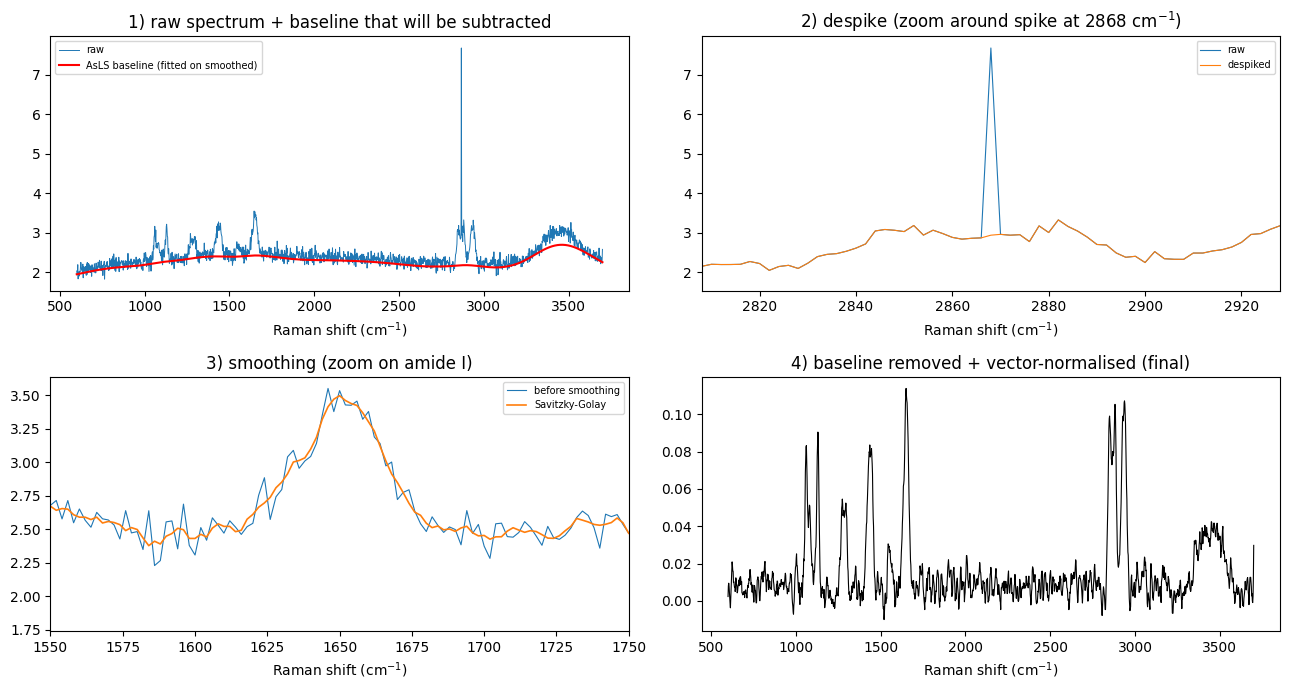

In [ ]:
# raman graph beore after details
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
ax[0, 0].plot(wn, y0, lw=0.7, label="raw")
ax[0, 0].plot(wn, bl + 0, c="r", lw=1.5, label="AsLS baseline (fitted on smoothed)")
ax[0, 0].set_title("1) raw spectrum + baseline that will be subtracted")
ax[0, 0].legend(fontsize=7)

ax[0, 1].plot(wn, y0, lw=0.8, label="raw") 
ax[0, 1].plot(wn, y1, lw=0.8, label="despiked")
ax[0, 1].set_xlim(spike_at - 60, spike_at + 60)
ax[0, 1].set_title(f"2) despike (zoom around spike at {spike_at:.0f} cm$^{{-1}}$)")
ax[0, 1].legend(fontsize=7)

ax[1, 0].plot(wn, y1, lw=0.8, label="before smoothing")
ax[1, 0].plot(wn, y2, lw=1.2, label="Savitzky-Golay")
ax[1, 0].set_xlim(1550, 1750)
ax[1, 0].set_title("3) smoothing (zoom on amide I)")
ax[1, 0].legend(fontsize=7)

ax[1, 1].plot(wn, y4, lw=0.8, c="k")
ax[1, 1].set_title("4) baseline removed + vector-normalised (final)")

for a in ax.ravel(): a.set_xlabel("Raman shift (cm$^{-1}$)")
show("fig04_preprocessing_steps")


# 3 -- Raman descriptor extraction
Raman has a lot of peak, thus we have to choose which peak is relevant. Maybe it can be searched from the position and height. We will do untargeted and targeted exploration. The targeted exploration refer to the defined raman area by any relevant publications.

In [14]:
# function helper -- analysis

def band_position(spec, lo, hi):
    """Peak position with sub-grid precision: fit a parabola through the top point and its 2 neighbours."""
    m = (wn >= lo) & (wn <= hi)
    idx = np.where(m)[0][np.argmax(spec[m])]
    y0, y1, y2 = spec[idx - 1], spec[idx], spec[idx + 1]
    return wn[idx] + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2) * (wn[1] - wn[0])

def height(spec, c, half=4):
    m = (wn >= c - half) & (wn <= c + half)
    return spec[m].max()

def area(spec, lo, hi):
    m = (wn >= lo) & (wn <= hi)
    return spec[m].sum() * (wn[1] - wn[0])

def _terms(spec): # the 1 or 2 measurements a descriptor is made of
    return list(spec[1:]) if spec[0] == "ratio" else [spec]

def _read(term, s): # measure one term on spectrum s
    kind = term[0]
    if kind == "h":   return height(s, term[1], term[2])
    if kind == "a":   return area(s, term[1], term[2])
    if kind == "pos": return band_position(s, term[1], term[2])
    raise ValueError(f"unknown term {term}")

def _window(term): # wavenumber window a term reads (used by the blind-scan plot)
    return (term[1] - term[2], term[1] + term[2]) if term[0] == "h" else (term[1], term[2])

def _label(term):  # short readable text for the plot axis
    return {"h": f"h{term[1]}", "a": f"A{term[1]}-{term[2]}", "pos": f"pos{term[1]}-{term[2]}"}[term[0]]

def _make(spec): # factory: builds the function s -> value (avoids the lambda-in-loop trap)
    t = _terms(spec)
    if spec[0] == "ratio": return lambda s: _read(t[0], s) / _read(t[1], s)
    return lambda s: _read(t[0], s)

# Pearson r after removing each group's mean
def within_r(a, b):                                         
    a, b = np.asarray(a, float).copy(), np.asarray(b, float).copy()
    for g in np.unique(grp): a[grp == g] -= a[grp == g].mean(); b[grp == g] -= b[grp == g].mean()
    return np.corrcoef(a, b)[0, 1]


In [15]:
# function helper -- untargeted analysis

# subtract each group's mean -> removes the group differences
def center_by_group(A, g):                                 
    A = np.asarray(A, float).copy()
    for k in np.unique(g): A[g == k] -= A[g == k].mean(0)
    return A

# Pearson r of EVERY column of A with y, in one matrix product
def colcorr(A, y):                                         
    A = (A - A.mean(0)) / (A.std(0) + 1e-12); y = (y - y.mean()) / y.std()
    return A.T @ y / len(y)

# Pearson r after removing each group's mean
def within_r(a, b):                                         
    a, b = a.astype(float).copy(), b.astype(float).copy()
    for g in np.unique(grp): a[grp == g] -= a[grp == g].mean(); b[grp == g] -= b[grp == g].mean()
    return np.corrcoef(a, b)[0, 1]

# blind scan
def blind_scan_plot(xlim=None):
    fig, ax = plt.subplots(5, 1, figsize=(13, 13), sharex=True, gridspec_kw=dict(height_ratios=[1, 1, 1, 1, 1.3]))
    for a in ax[:4]: # yellow = every region that at least one targeted descriptor reads
        for lo, hi in {w for v in TARGETED.values() for w in v}: a.axvspan(lo, hi, color="#e9c46a", alpha=.28, lw=0)
    
    ax[0].plot(wn, Xt.mean(0), c="k", lw=.8)
    ax[0].set_ylabel("mean spectrum")
    ax[0].set_title("Blind scan of the spectra (3 training groups).  Yellow = regions the targeted descriptors look at")
    
    ax[1].plot(wn, r_pooled, c="#8d99ae", lw=.8, label="pooled r (mixes groups)")
    ax[1].plot(wn, r_within, c="#9b2226", lw=.9, label="within-group r (groups removed)")
    ax[1].axhline(0, c="k", lw=.4); ax[1].set_ylabel("r with ln flux")
    ax[1].legend(fontsize=7)
    
    ax[2].plot(wn, r_order, c="#2a9d8f", lw=.9)
    ax[2].axhline(0, c="k", lw=.4)
    ax[2].set_ylabel("within-group r with\nTRUE lipid order")
    
    ax[3].plot(wn, vip, c="#264653", lw=.9)
    ax[3].axhline(1, c="r", ls="--", lw=.8)
    ax[3].set_ylabel("PLS VIP (spectra only)")
    
    for i, (name, wins) in enumerate(TARGETED.items()): # bottom panel: one row per descriptor, bar = the window(s) it reads
        for lo, hi in wins: ax[4].barh(i, max(hi - lo, 6), left=lo, height=.6, color="#e9c46a", edgecolor="#b08900")
    
    ax[4].set_yticks(range(len(TARGETED)))
    ax[4].set_yticklabels([f"{k}   [{DESC_FORMULA[k]}]" for k in TARGETED], fontsize=8)   # name + what it measures
    ax[4].invert_yaxis()
    ax[4].set_ylabel("targeted descriptor")
    ax[4].set_xlabel("Raman shift (cm$^{-1}$)")
    
    if xlim: ax[4].set_xlim(*xlim) # zoom, e.g. blind_scan_plot((2800, 3000))
    show("fig_blind_scan" + ("" if not xlim else f"_{xlim[0]}_{xlim[1]}"))

# checker whether its already read by a targeted descriptor?
def in_targeted(w):               
    hits = [k for k, wins in TARGETED.items() if any(lo <= w <= hi for lo, hi in wins)]
    return ", ".join(hits) if hits else "NEW (not covered)"

In [16]:
# define targeted descriptors

#   ("h",   c, half)  = highest point within c +- half     (height)
#   ("a",   lo, hi)   = area between lo and hi             (band area)
#   ("pos", lo, hi)   = peak position inside lo..hi        (sub-grid precision)
#   ("ratio", top, bottom) = top / bottom
DESC_SPEC = {
    "nu_s_CH2_pos":    ("pos", 2835, 2870),
    "r_2880_2850":     ("ratio", ("h", 2880, 4),  ("h", 2852, 4)),
    "r_1130_1080":     ("ratio", ("h", 1130, 4),  ("h", 1080, 12)),
    "r_1062_1080":     ("ratio", ("h", 1062, 4),  ("h", 1080, 12)),
    "r_1296_1440":     ("ratio", ("h", 1296, 4),  ("h", 1440, 6)),
    "r_amideI_CH2":    ("ratio", ("h", 1652, 6),  ("h", 1440, 6)),
    "r_lipid_protein": ("ratio", ("a", 2830, 2900), ("a", 2900, 2980)),
    "r_water_protein": ("ratio", ("a", 3300, 3600), ("a", 2900, 2980)),
}
DESC     = {k: _make(v) for k, v in DESC_SPEC.items()} 
DESC_FORMULA = {k: " / ".join(_label(t) for t in _terms(v)) for k, v in DESC_SPEC.items()}

desc = pd.DataFrame({k: [f(s) for s in X] for k, f in DESC.items()})

In [17]:
# Targeted exploration
# needs: desc (from DESC), meta, GROUPS, COL, OUT, show
missing = [n for n in ("desc", "meta", "GROUPS", "COL", "OUT", "show") if n not in globals()]
if missing: raise NameError(f"Run the descriptor cell first. Missing: {missing}")
assert len(desc) == len(meta), "desc and meta must have the same rows"

REFS = {"true lipid order": meta.true_order.values, "measured hydration": meta.hydration.values, "measured TEWL": meta.tewl.values}
grp = meta.group.values

# 1. table: pooled r, within-group r, Spearman rho, for every descriptor x reference
rows = []
for c in desc.columns:
    row = dict(descriptor=c)
    for name, ref in REFS.items():
        s = desc[c].values
        row[f"r_pooled | {name}"] = np.corrcoef(s, ref)[0, 1]
        row[f"r_within | {name}"] = within_r(s, ref)
        row[f"rho | {name}"]      = spearmanr(s, ref)[0]
    rows.append(row)
rel_t = pd.DataFrame(rows).set_index("descriptor").round(2)
# rel_t.to_csv(OUT / "12_targeted_descriptor_relations.csv")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(rel_t.to_string())

# 2. what each descriptor reports best INSIDE groups, and whether it matches the design
EXPECT = {"nu_s_CH2_pos": "true lipid order", "r_2880_2850": "true lipid order", "r_1130_1080": "true lipid order", "r_1062_1080": "true lipid order", "r_water_protein": "measured hydration"} # what each is meant to report
best_t = pd.DataFrame({"best_reference": [max(REFS, key=lambda n: abs(rel_t.loc[c, f"r_within | {n}"])) for c in rel_t.index], "within_r": [max((rel_t.loc[c, f"r_within | {n}"] for n in REFS), key=abs) for c in rel_t.index]}, index=rel_t.index)
best_t["meant_to_report"] = [EXPECT.get(c, "-") for c in best_t.index]
best_t["as_designed"] = [("yes" if r == e else "NO") if e != "-" else "-" for r, e in zip(best_t.best_reference, best_t.meant_to_report)]

print("\nwhat each targeted descriptor reports best (inside groups):"); print(best_t.to_string())

                 r_pooled | true lipid order  r_within | true lipid order  rho | true lipid order  r_pooled | measured hydration  r_within | measured hydration  rho | measured hydration  r_pooled | measured TEWL  r_within | measured TEWL  rho | measured TEWL
descriptor                                                                                                                                                                                                                                                        
nu_s_CH2_pos                           -0.48                        -0.23                   -0.48                          -0.21                          -0.05                     -0.21                      0.26                      0.03                 0.27
r_2880_2850                             0.90                         0.62                    0.89                           0.31                           0.03                      0.29                     -0.48            

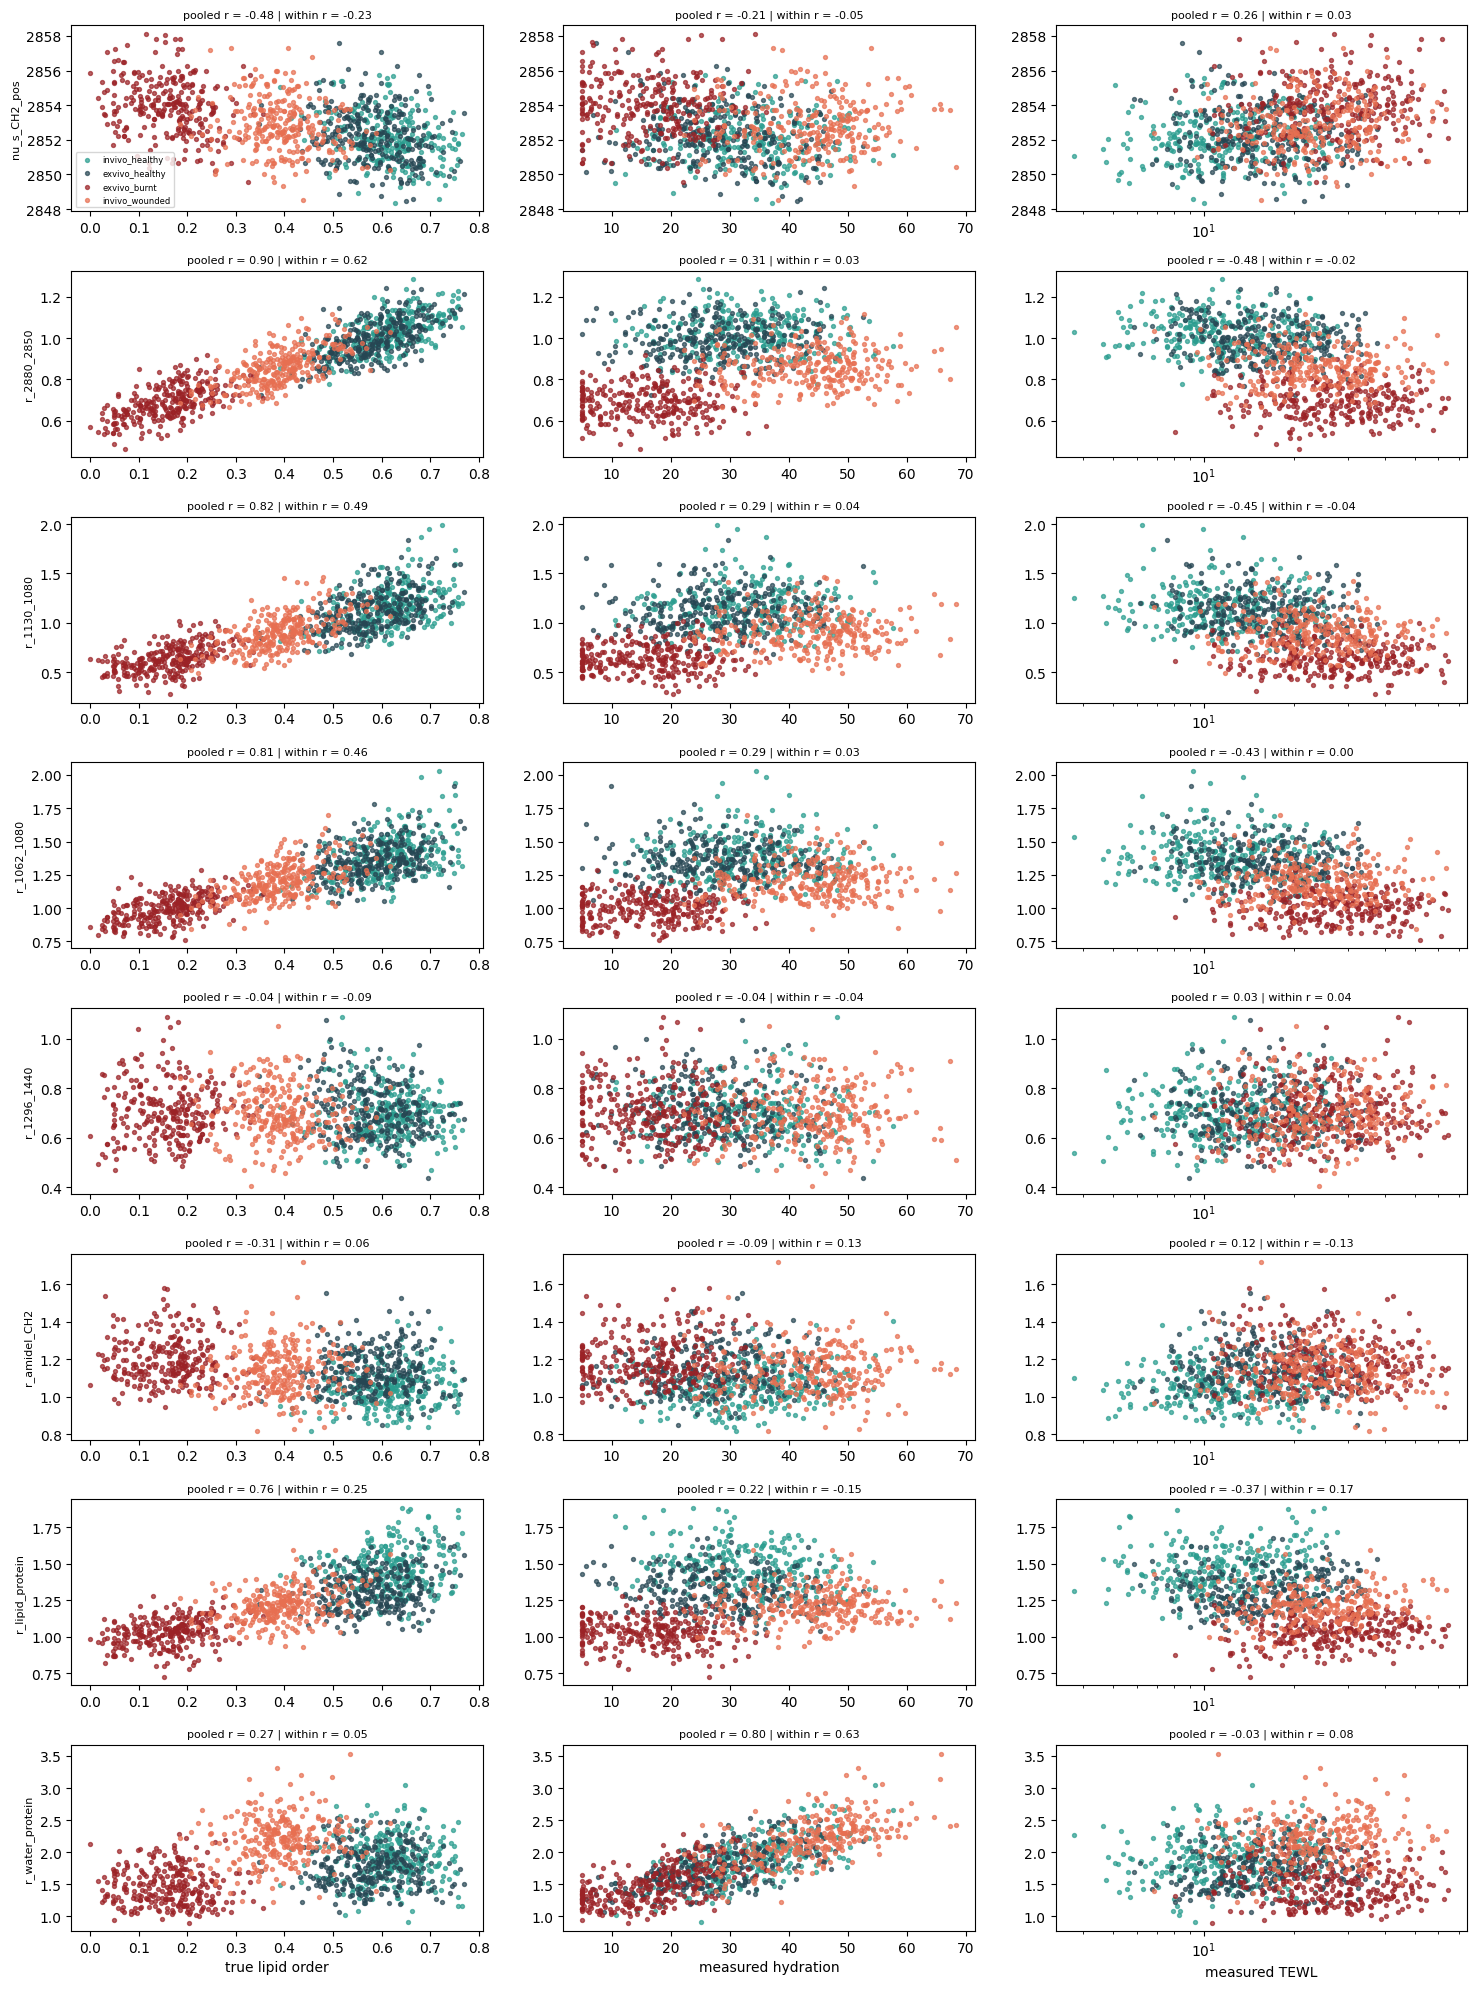

In [ ]:
# relations of the descriptors to true lipid order, TEWL, and hydration
n = len(desc.columns)
fig, ax = plt.subplots(n, 3, figsize=(15, 2.5 * n), squeeze=False)
for i, c in enumerate(desc.columns):
    for j, (name, ref) in enumerate(REFS.items()):
        a = ax[i, j]
        for g in GROUPS:
            m = (grp == g)
            a.scatter(ref[m], desc[c].values[m], s=8, c=COL[g], alpha=.7, label=g)
        a.set_xlabel(name if i == n - 1 else "")
        a.set_ylabel(c if j == 0 else "", fontsize=8)
        a.set_title(f"pooled r = {rel_t.loc[c, f'r_pooled | {name}']:.2f} | within r = {rel_t.loc[c, f'r_within | {name}']:.2f}", fontsize=8)
        if name == "measured TEWL": a.set_xscale("log")
ax[0, 0].legend(fontsize=6)
show("fig05_targeted_descriptor_validity")

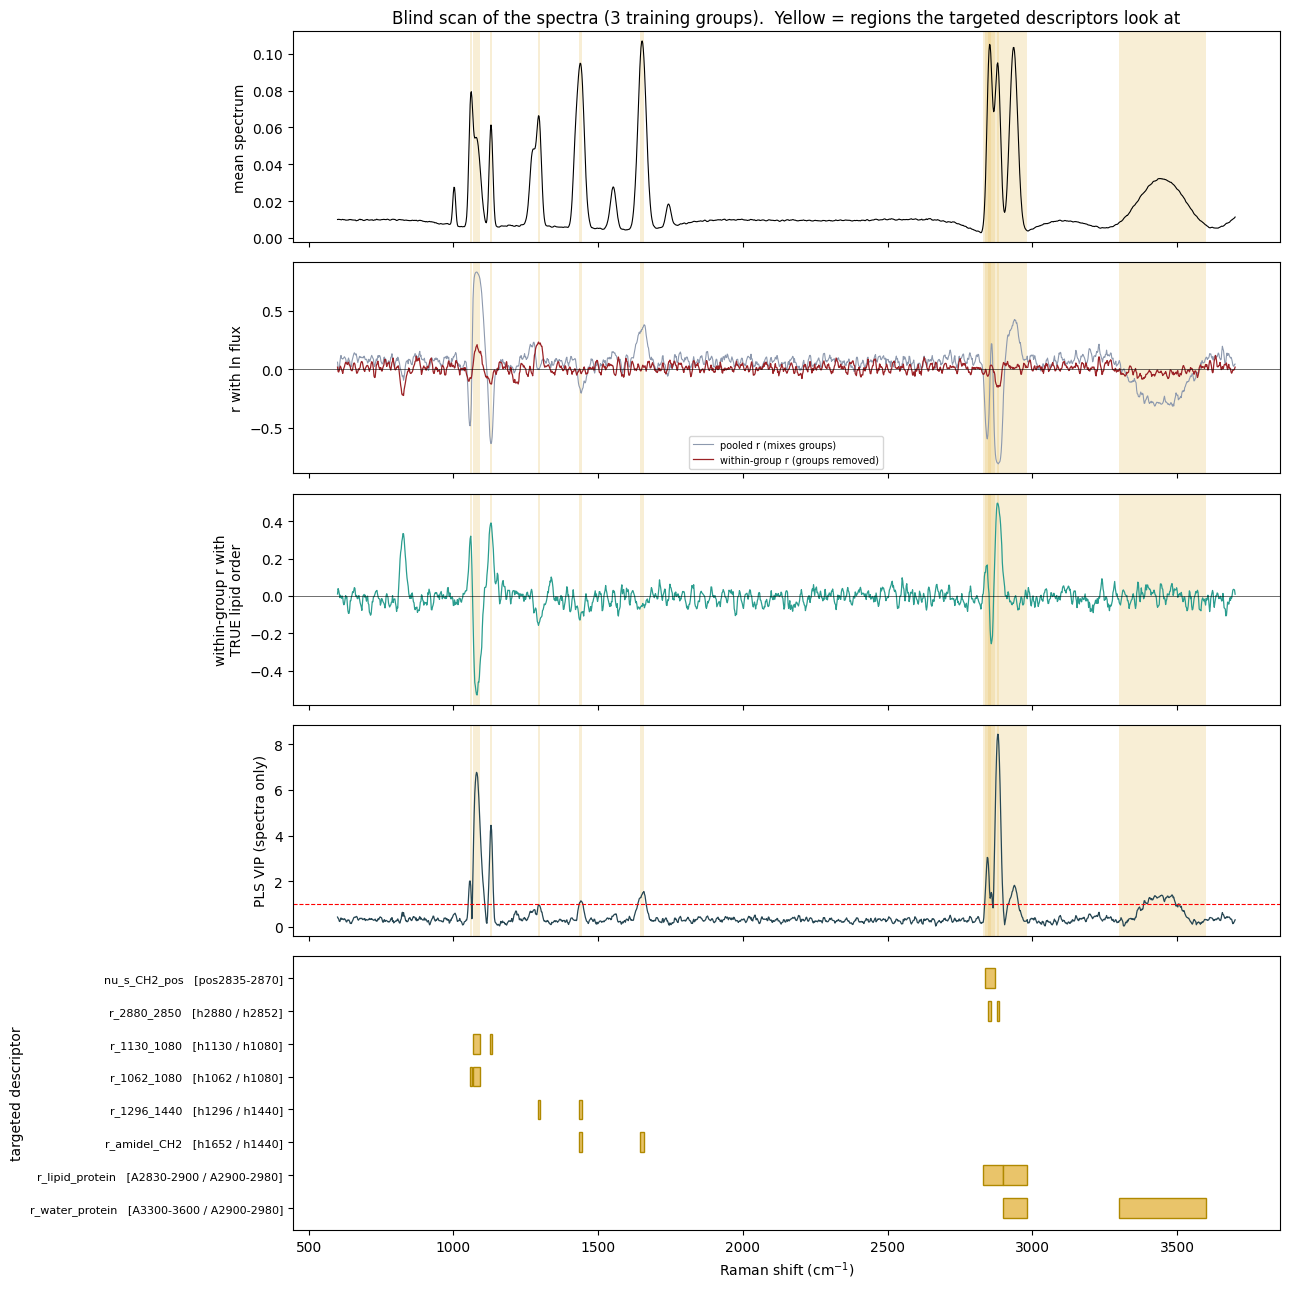

In [19]:
# untargeted exploration
TARGETED = {k: [_window(t) for t in _terms(v)] for k, v in DESC_SPEC.items()}

# needs: X (preprocessed spectra), meta (simulation table), wn, TRAIN_GROUPS
tr = meta.group.isin(TRAIN_GROUPS).values    
Xt, yt, gt = X[tr], np.log(meta.flux.values[tr]), meta.group.values[tr]   # target = ln flux
ot = meta.true_order.values[tr]  # TRUE hidden lipid order: only exists in a simulation 

r_pooled = colcorr(Xt, yt) # mixes group differences with real signal
r_within = colcorr(center_by_group(Xt, gt), center_by_group(yt[:, None], gt).ravel())       # signal INSIDE the groups only
r_order  = colcorr(center_by_group(Xt, gt), center_by_group(ot[:, None], gt).ravel())       # within-group r with the TRUE lipid order

# PLS on the whole spectrum, then VIP = importance of each wavenumber (VIP > 1 = above-average importance)
N_LV_BLIND = 2 # check with donor-grouped CV
pls_blind = PLSRegression(n_components=N_LV_BLIND, scale=False).fit(Xt - Xt.mean(0), yt - yt.mean())
W, T, Q = pls_blind.x_weights_, pls_blind.x_scores_, pls_blind.y_loadings_
ss = (Q.ravel() ** 2) * (T ** 2).sum(0) # y-variance explained by each LV
vip = np.sqrt(Xt.shape[1] * ((W / np.linalg.norm(W, axis=0)) ** 2 @ ss) / ss.sum())

# dont forget to provide vip score first
blind_scan_plot() 
# blind_scan_plot((1000, 1150))  # lipid C-C region, where 1062 / 1080 / 1130 live

bands found in the mean spectrum: [1002, 1062, 1130, 1294, 1438, 1552, 1652, 1744, 2646, 2852, 2880, 2936, 3094, 3440]
untargeted descriptor table: (1080, 8)
                wn  r_within_flux   VIP                     covered_by  r_pooled | true lipid order  r_within | true lipid order  rho | true lipid order  r_pooled | measured hydration  r_within | measured hydration  rho | measured hydration  r_pooled | measured TEWL  r_within | measured TEWL  rho | measured TEWL
descriptor                                                                                                                                                                                                                                                                                                               
I_1008      1008.0           0.07  0.54              NEW (not covered)                        -0.13                        -0.05                   -0.13                          -0.08                          -0.02

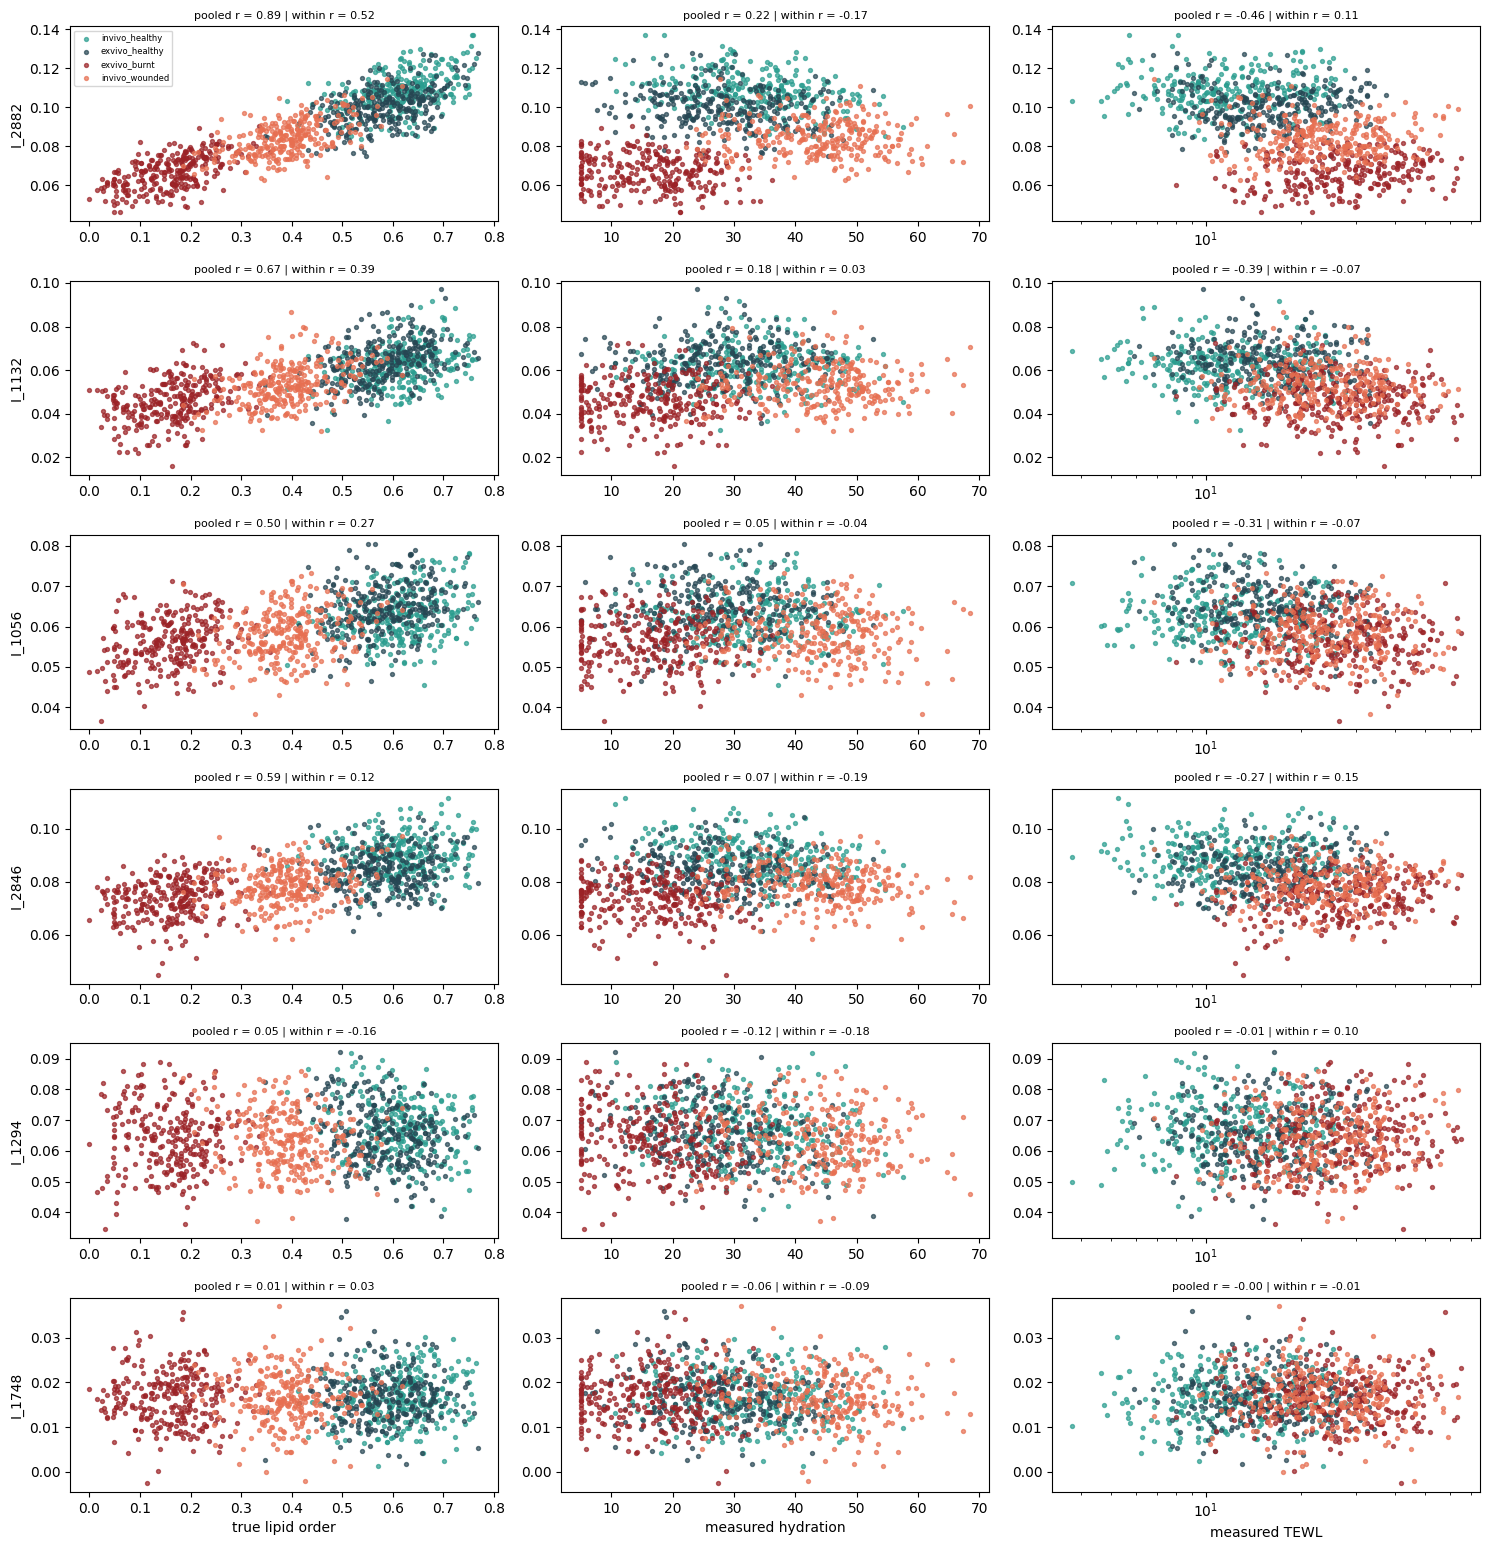

In [ ]:
# relation of the descriptors found in untargeted to true lipid order / hydration / TEWL

# needs from the blind-scan cell: r_within, vip, TARGETED, Xt, wn, X, meta ;  plus GROUPS, COL, OUT, show
missing = [n for n in ("r_within", "vip", "TARGETED", "Xt", "wn", "X", "meta", "GROUPS", "COL", "show") if n not in globals()]
if missing: raise NameError(f"Run the blind-scan cell first. Missing: {missing}")

# 1. pick the wavenumbers
# Only look at real spectral bands. Smooth regions (the 600-800 edge, valleys) can correlate strongly with flux just because of normalisation / baseline (closure effect), not because of chemistry. 
# Find the bands in the mean spectrum first, then take, near each band, the point where |within-group r| with ln flux is largest.
N_DESC, BAND_ONLY, EDGE = 8, True, 40    # EDGE = cm-1 ignored at both ends of the axis
mean_sp = Xt.mean(0)
if BAND_ONLY:
    bands, _ = find_peaks(mean_sp, prominence=0.03 * np.ptp(mean_sp))  # real bands 
    bands = [b for b in bands if wn[b] > wn.min() + EDGE and wn[b] < wn.max() - EDGE]
    cand = np.array([b + np.argmax(np.abs(r_within[max(b - 3, 0):b + 4])) - min(3, b) for b in bands])  # best point within +-6 cm-1
    cand = np.unique(cand)
else:
    cand, _ = find_peaks(np.abs(r_within), height=.3 * np.abs(r_within).max(), distance=8)
pk = cand[np.argsort(-np.abs(r_within[cand]))][:N_DESC]
pk = pk[np.argsort(wn[pk])]  # sort by wavenumber for reading
print("bands found in the mean spectrum:", [int(wn[b]) for b in (bands if BAND_ONLY else [])])


# 2. the dataframe: one column per found wavenumber (mean of 3 points = 6 cm-1 to reduce noise), 432 rows like meta
blind_desc = pd.DataFrame({f"I_{wn[j]:.0f}": X[:, max(j - 1, 0):j + 2].mean(1) for j in pk})
blind_desc.to_csv(OUT / "11_untargeted_descriptors.csv", index=False)
print("untargeted descriptor table:", blind_desc.shape)

# 3. relation to the three references ----
REFS = {"true lipid order": meta.true_order.values, "measured hydration": meta.hydration.values, "measured TEWL": meta.tewl.values}
grp = meta.group.values

rows = []
for j, c in zip(pk, blind_desc.columns):
    row = dict(descriptor=c, wn=wn[j], r_within_flux=r_within[j], VIP=vip[j], covered_by=in_targeted(wn[j]))
    for name, ref in REFS.items():
        s = blind_desc[c].values
        row[f"r_pooled | {name}"] = np.corrcoef(s, ref)[0, 1]
        row[f"r_within | {name}"] = within_r(s, ref)
        row[f"rho | {name}"]      = spearmanr(s, ref)[0]
    rows.append(row)
rel = pd.DataFrame(rows).set_index("descriptor").round(2)
rel.to_csv(OUT / "11_untargeted_descriptor_relations.csv")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(rel.to_string())

# best match of each descriptor (largest within-group |r|): which property does it report?
best = pd.DataFrame({"best_reference": [max(REFS, key=lambda n: abs(rel.loc[c, f"r_within | {n}"])) for c in rel.index],
                     "within_r": [max((rel.loc[c, f"r_within | {n}"] for n in REFS), key=abs) for c in rel.index],
                     "covered_by": rel.covered_by}, index=rel.index)
print("\nwhat each untargeted descriptor reports best (inside groups):"); print(best.to_string())

# 4. graph
N_PLOT = min(6, len(pk))
top_plot = rel.assign(m=rel[[f"r_within | {n}" for n in REFS]].abs().max(axis=1)).sort_values("m", ascending=False).index[:N_PLOT]

fig, ax = plt.subplots(N_PLOT, 3, figsize=(15, 2.6 * N_PLOT), squeeze=False)
for i, c in enumerate(top_plot):
    for j_, (name, ref) in enumerate(REFS.items()):
        a = ax[i, j_]
        for g in GROUPS:
            m = (grp == g)
            a.scatter(ref[m], blind_desc[c].values[m], s=8, c=COL[g], alpha=.7, label=g)
        a.set_xlabel(name if i == N_PLOT - 1 else "")
        a.set_ylabel(c if j_ == 0 else "")
        a.set_title(f"pooled r = {rel.loc[c, f'r_pooled | {name}']:.2f} | within r = {rel.loc[c, f'r_within | {name}']:.2f}", fontsize=8)
        if name == "measured TEWL": a.set_xscale("log")

ax[0, 0].legend(fontsize=6)
show("fig06_untargeted_descriptor_validity")

# 4 -- multi-block data fusion
Different instruments have different blocks describing the same 432 measurements (rows):
  block 1 spectra (1551 vars) | block 2 Raman descriptors (8) | block 3 biophysical (3).

Problem: block 1 has 1551 variables and would drown the 3 biophysical ones. 

Fix = block scaling:
autoscale (mean 0, sd 1) and divide each block so its total variance = 1 -> every block gets equal say. Flux is the target.

In [21]:
# fusion
bio  = pd.DataFrame({"hydration": meta.hydration, "log_sebum": np.log(meta.sebum),
                     "log_tewl": np.log(meta.tewl)})
BLOCKS = {"spectra": X, "raman_desc": desc.values, "biophys": bio.values}
BLOCK_VARS = {"spectra": [f"{w:.0f}" for w in wn], "raman_desc": list(desc.columns), "biophys": list(bio.columns)}

D = pd.concat([meta, desc, bio[["log_sebum", "log_tewl"]]], axis=1) # 'hydration' already in meta
D["ln_flux"] = np.log(D.flux) # model target on log scale
D["site_arm"] = (D.site == "arm").astype(float); D["site_leg"] = (D.site == "leg").astype(float)
# D.to_csv(OUT / "02_multiblock_dataset_replicate_level.csv", index=False)
# np.save(OUT / "02_spectra_preprocessed.npy", X); np.save(OUT / "02_wavenumber.npy", wn)
print("blocks:", {k: v.shape for k, v in BLOCKS.items()}, "| rows:", len(D))

DESC_COLS = list(desc.columns) + list(bio.columns) # descriptor-level block = 8 Raman + 3 biophysical = 11
D_desc = pd.concat([desc, bio], axis=1)
assert not any("flux" in c for c in DESC_COLS) # guard: the target must never be a predictor

RAMAN, BIO = list(desc.columns), list(bio.columns)
DESC_COLS = RAMAN + BIO # descriptor-level block = 8 Raman + 3 biophysical = 11 predictors
D_desc = pd.concat([desc, bio], axis=1)
assert not any("flux" in c for c in DESC_COLS) # guard: the target must never be a predictor

idx_all = np.arange(len(D))
idx_tr  = np.where(D.group.isin(TRAIN_GROUPS))[0] # rows of the 3 training groups
idx_te  = np.where(D.group == TEST_GROUP)[0]  # rows of wounded: the BLIND test rows


blocks: {'spectra': (1080, 1551), 'raman_desc': (1080, 8), 'biophys': (1080, 3)} | rows: 1080


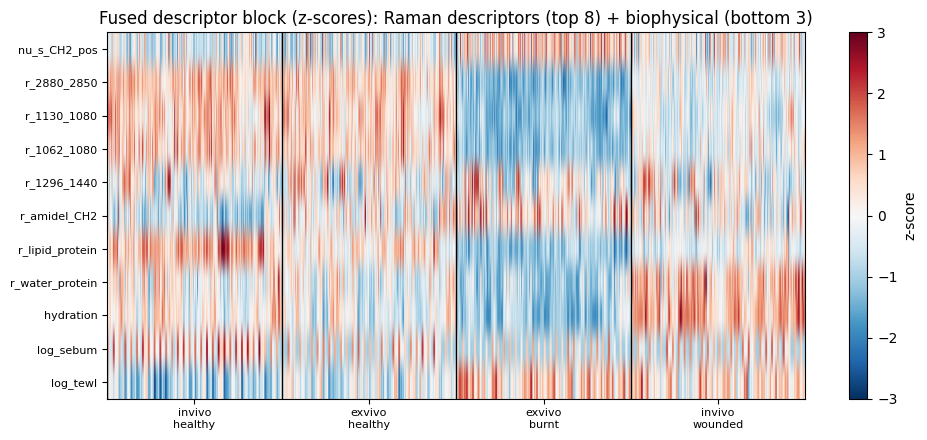

In [ ]:
# heatmap of the blocks
Zview = (D_desc - D_desc.mean()) / D_desc.std() # how far is the group std compared to the pop
order_rows = np.argsort(pd.Categorical(meta.group, categories=GROUPS).codes, kind="stable")

# graph
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(Zview.values[order_rows].T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)

ax.set_yticks(range(len(DESC_COLS)))
ax.set_yticklabels(DESC_COLS, fontsize=8)
edges_ = np.cumsum([0] + [(meta.group == g).sum() for g in GROUPS])
for e in edges_[1:-1]: ax.axvline(e - 0.5, c="k", lw=1)
ax.set_xticks((edges_[:-1] + edges_[1:]) / 2 - 0.5)
ax.set_xticklabels([g.replace("_", "\n") for g in GROUPS], fontsize=8)

ax.set_title("Fused descriptor block (z-scores): Raman descriptors (top 8) + biophysical (bottom 3)")
plt.colorbar(im, ax=ax, label="z-score")
show("fig07_fused_block_heatmap")


# 5 -- PCA of the fused descriptors, without flux

In [23]:
# function helper -- analysis

def autoscale(A): return (A - A.mean(0)) / A.std(0, ddof=1)

def relevance(Z, y, n_pc=5):
    p = PCA(n_components=min(n_pc, Z.shape[1])).fit(Z)
    T = p.transform(Z)
    r2 = np.array([np.corrcoef(T[:, k], y)[0, 1] ** 2 for k in range(T.shape[1])])
    rel = (np.abs(p.components_) * r2[:, None]).sum(0)
    return rel / rel.max()  # scaled so the best descriptor = 1.00

def pca_by_site(T, evr, title, fname):
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    # left: colour = site, marker = group
    for s in SITES:
        for g in GROUPS:
            m = ((D.site == s) & (D.group == g)).values
            ax[0].scatter(T[m, 0], T[m, 1], s=22, c=SITE_COL[s], marker=SITE_MK[g], alpha=.75,
                          edgecolors="k", linewidths=.3, label=f"{s} | {g}")
    ax[0].set_title(title + ": colour = site, marker = group")
    # right: colour = site only, with the site centroid
    for s in SITES:
        m = (D.site == s).values
        ax[1].scatter(T[m, 0], T[m, 1], s=18, c=SITE_COL[s], alpha=.6, label=s)
        ax[1].scatter(T[m, 0].mean(), T[m, 1].mean(), s=200, c=SITE_COL[s], marker="X", edgecolors="k", linewidths=1.2)
    ax[1].set_title(title + ": colour = site (X = site centroid)")
    for a in ax:
        a.axhline(0, c="k", lw=.4); a.axvline(0, c="k", lw=.4)
        a.set_xlabel(f"PC1 ({evr[0]*100:.0f}%)"); a.set_ylabel(f"PC2 ({evr[1]*100:.0f}%)")
    ax[0].legend(fontsize=6, ncol=2, loc="best"); ax[1].legend(fontsize=8)
    show(fname)

def get_blocks(idx): return {n: BLOCKS[n][idx] for n in BLOCKS}

def block_fit(idx):
    """Learn mean / sd / block weight from the given (training) rows only. Spectra: centre only (they are already normalised)."""
    sc = {}
    for n, A in get_blocks(idx).items():
        mu = A.mean(0); sd = A.std(0, ddof=1) if n != "spectra" else np.ones(A.shape[1])
        sc[n] = (mu, sd, np.sqrt(((A - mu) / sd).var(0, ddof=1).sum()))      # block weight: total variance of the block = 1
    return sc

def block_apply(sc, idx):
    b = get_blocks(idx)
    return np.hstack([((b[n] - mu) / sd) / nrm for n, (mu, sd, nrm) in sc.items()])

In [27]:
# analyse PCA
N_PC = 5                                                   # one place to change the number of components (original notebook: 5)

is_train = D.group.isin(TRAIN_GROUPS).values               # boolean mask: rows of the 3 training groups
Z_all = autoscale(D_desc.values)
pca_all = PCA(n_components=N_PC).fit(Z_all); T_all = pca_all.transform(Z_all)
load_all = pd.DataFrame(pca_all.components_.T[:, :3], index=DESC_COLS, columns=["PC1", "PC2", "PC3"])

Ztr_d = autoscale(D_desc.values[is_train])
ytr = D.ln_flux.values[is_train]
pca_tr = PCA(n_components=N_PC).fit(Ztr_d)
Ttr = pca_tr.transform(Ztr_d)
r_pc = np.array([np.corrcoef(Ttr[:, k], ytr)[0, 1] for k in range(Ttr.shape[1])])   # follows the real number of PCs

rel_tr = relevance(Ztr_d, ytr, n_pc=N_PC)
rank_tbl = pd.DataFrame({"loading_PC1": pca_tr.components_[0], "loading_PC2": pca_tr.components_[1], "loading_PC3": pca_tr.components_[2],
                         "relevance_to_flux": rel_tr,
                         "spearman_vs_lnflux": [spearmanr(D_desc.values[is_train][:, j], ytr)[0] for j in range(len(DESC_COLS))]},
                        index=DESC_COLS).sort_values("relevance_to_flux", ascending=False).round(3)
rank_tbl.to_csv(OUT / "03_pca_loadings_and_relevance_training.csv"); load_all.round(3).to_csv(OUT / "03_pca_loadings_all_groups.csv")

print(f"PCA on the training groups ({Ztr_d.shape[0]} rows), explained variance:", pca_tr.explained_variance_ratio_.round(3))
print("corr(PC score, ln flux):", r_pc.round(2))
print("\nLoadings + relevance (training groups):"); print(rank_tbl.to_string())
print("\nPCA on all 4 groups, explained variance:", pca_all.explained_variance_ratio_.round(3))

PCA on the training groups (810 rows), explained variance: [0.444 0.134 0.103 0.077 0.074]
corr(PC score, ln flux): [-0.84  0.08  0.02 -0.02  0.15]

Loadings + relevance (training groups):
                 loading_PC1  loading_PC2  loading_PC3  relevance_to_flux  spearman_vs_lnflux
r_2880_2850            0.400       -0.013        0.086              1.000              -0.693
r_1062_1080            0.387       -0.036        0.111              0.981              -0.682
r_1130_1080            0.385       -0.057        0.103              0.978              -0.686
r_lipid_protein        0.375        0.198       -0.122              0.936              -0.648
hydration              0.305       -0.447       -0.168              0.788              -0.495
log_tewl              -0.304       -0.216       -0.235              0.772               0.535
r_water_protein        0.261       -0.462       -0.193              0.694              -0.408
nu_s_CH2_pos          -0.266        0.108       -0.188     

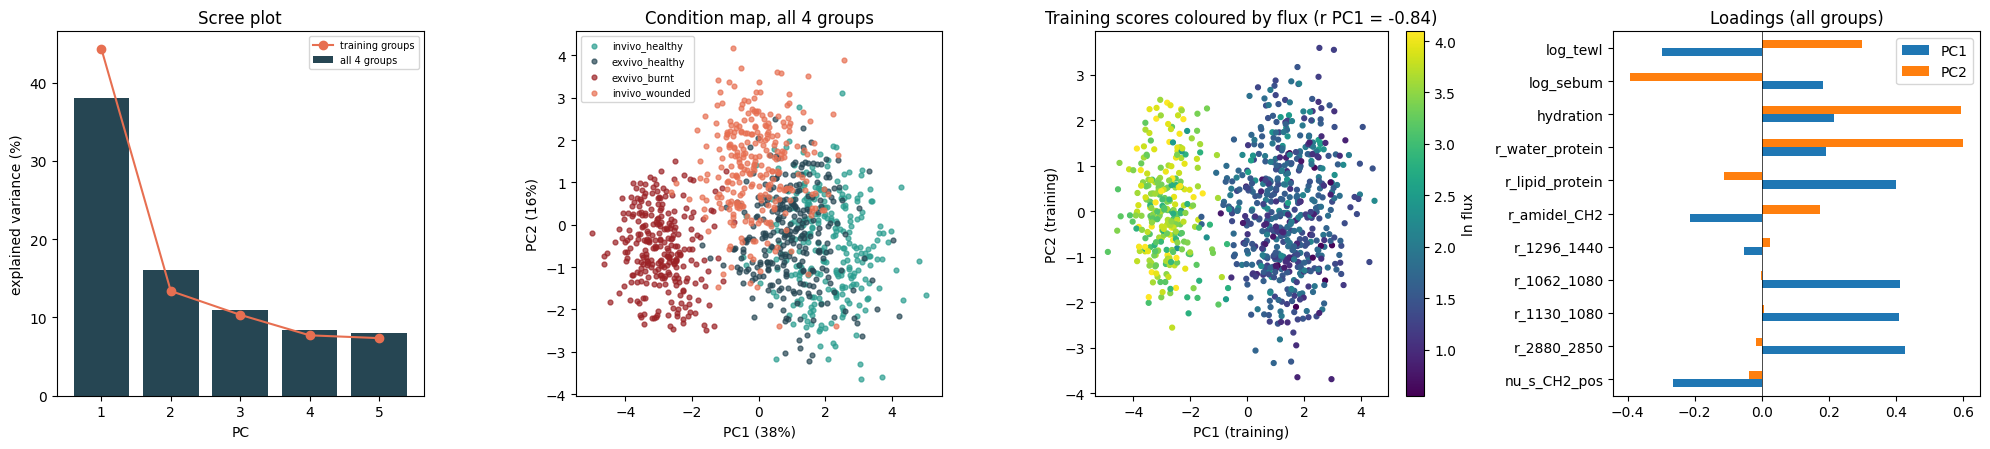

In [28]:
# PCA score plot
fig, ax = plt.subplots(1, 4, figsize=(20, 4.6))

ax[0].bar(range(1, 6), pca_all.explained_variance_ratio_ * 100, color="#264653", label="all 4 groups")
ax[0].plot(range(1, 6), pca_tr.explained_variance_ratio_ * 100, "o-", c="#e76f51", label="training groups")
ax[0].set_xlabel("PC"); ax[0].set_ylabel("explained variance (%)")
ax[0].set_title("Scree plot"); ax[0].legend(fontsize=7)
for g in GROUPS:
    m = (D.group == g).values; ax[1].scatter(T_all[m, 0], T_all[m, 1], s=12, c=COL[g], label=g, alpha=.7)

ax[1].set_xlabel(f"PC1 ({pca_all.explained_variance_ratio_[0]*100:.0f}%)")
ax[1].set_ylabel(f"PC2 ({pca_all.explained_variance_ratio_[1]*100:.0f}%)")
ax[1].set_title("Condition map, all 4 groups")
ax[1].legend(fontsize=7)
sc_ = ax[2].scatter(Ttr[:, 0], Ttr[:, 1], c=ytr, cmap="viridis", s=12)
plt.colorbar(sc_, ax=ax[2], label="ln flux")

ax[2].set_xlabel("PC1 (training)"); ax[2].set_ylabel("PC2 (training)")
ax[2].set_title(f"Training scores coloured by flux (r PC1 = {r_pc[0]:.2f})")

load_all[["PC1", "PC2"]].plot.barh(ax=ax[3]); ax[3].axvline(0, c="k", lw=.5)
ax[3].set_title("Loadings (all groups)")
show("fig08_pca_scores_loadings")


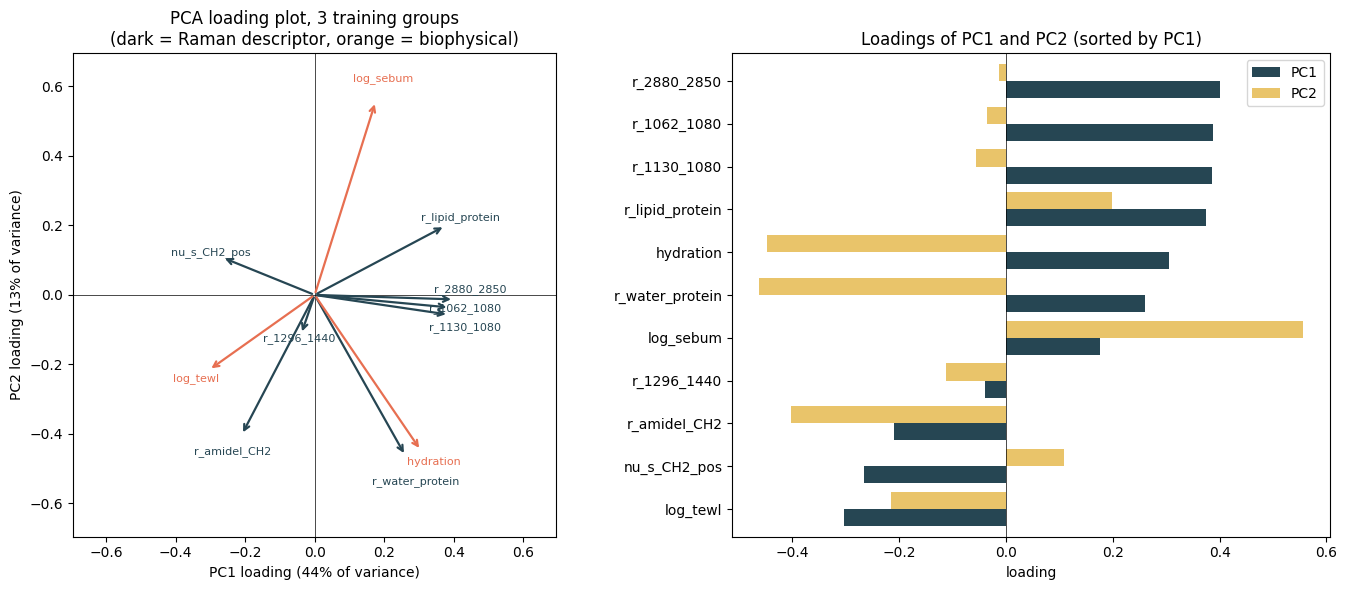

In [29]:
# PCA loading plot

load = pd.DataFrame(pca_tr.components_[:2].T, index=DESC_COLS, columns=["PC1", "PC2"])   # weight of each descriptor in PC1 / PC2
ev = pca_tr.explained_variance_ratio_ * 100     # % variance of each PC
kind_col = lambda name: "#264653" if name in RAMAN else "#e76f51"  # dark = Raman, orange = biophysical

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
lab = load.values * 1.12  # label positions
for _ in range(60):  # spread labels that would overlap
    for i in range(len(lab)):
        for j in range(i + 1, len(lab)):
            dx, dy = lab[i] - lab[j]
            if abs(dx) < 0.25 and abs(dy) < 0.05:
                sgn = 1 if (dy > 0 or (dy == 0 and i < j)) else -1
                lab[i, 1] += sgn * 0.01; lab[j, 1] -= sgn * 0.01
for i, (name, (x, y)) in enumerate(load.iterrows()):
    ax[0].annotate("", xy=(x, y), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=kind_col(name), lw=1.6))
    ax[0].text(lab[i, 0], lab[i, 1], name, color=kind_col(name), fontsize=8, ha="center", va="center")
lim = 1.25 * np.abs(load.values).max()

ax[0].set_xlim(-lim, lim); ax[0].set_ylim(-lim, lim)
ax[0].set_aspect("equal")
ax[0].axhline(0, c="k", lw=.5); ax[0].axvline(0, c="k", lw=.5)
ax[0].set_xlabel(f"PC1 loading ({ev[0]:.0f}% of variance)"); ax[0].set_ylabel(f"PC2 loading ({ev[1]:.0f}% of variance)")
ax[0].set_title("PCA loading plot, 3 training groups\n(dark = Raman descriptor, orange = biophysical)")

load.sort_values("PC1").plot.barh(ax=ax[1], width=.8, color=["#264653", "#e9c46a"])
ax[1].axvline(0, c="k", lw=.5); ax[1].set_xlabel("loading"); ax[1].set_title("Loadings of PC1 and PC2 (sorted by PC1)")
show("fig09_pca_loading_plot")

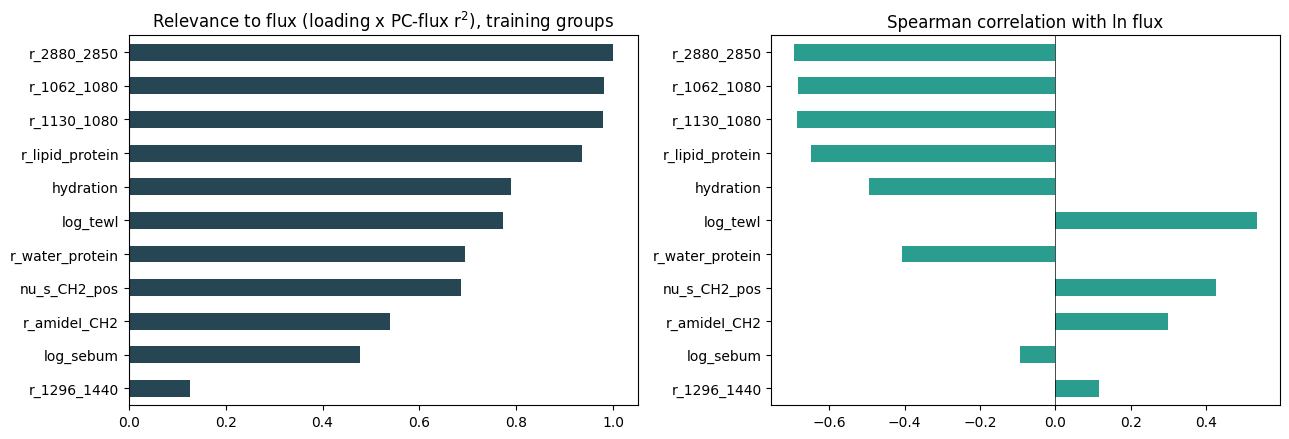

In [30]:
# Explore the relationship between the descriptor and the flux

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
rank_tbl["relevance_to_flux"].iloc[::-1].plot.barh(ax=ax[0], color="#264653")

ax[0].set_title("Relevance to flux (loading x PC-flux r$^2$), training groups")
rank_tbl["spearman_vs_lnflux"].iloc[::-1].plot.barh(ax=ax[1], color="#2a9d8f")
ax[1].axvline(0, c="k", lw=.5); ax[1].set_title("Spearman correlation with ln flux")

show("fig10_descriptor_relevance")

multi-block PCA (training rows) explained variance: [0.319 0.139 0.064 0.055 0.046]
PC1 loading energy by block: {'spectra': 0.1, 'raman_desc': 0.45, 'biophys': 0.45}
PC2 loading energy by block: {'spectra': 0.04, 'raman_desc': 0.11, 'biophys': 0.85}


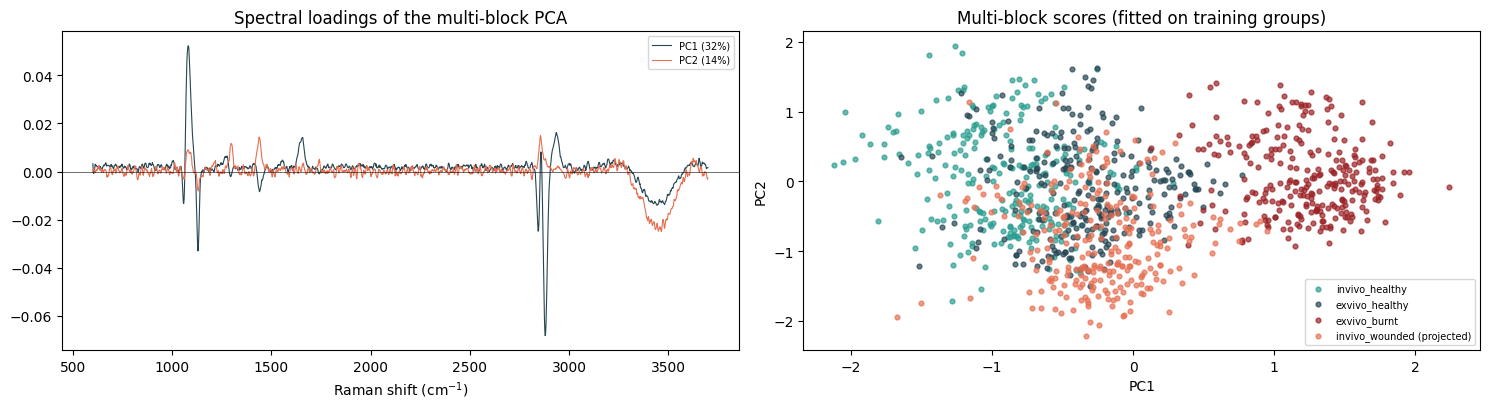

In [31]:
# full multi-block PCA

sc_full = block_fit(idx_tr)
pca_mb = PCA(n_components=5).fit(block_apply(sc_full, idx_tr))
Tmb = pca_mb.transform(block_apply(sc_full, idx_all))
nsp, nrd = X.shape[1], len(RAMAN)

print("multi-block PCA (training rows) explained variance:", pca_mb.explained_variance_ratio_.round(3))
for k in range(2):
    ld = pca_mb.components_[k]
    print(f"PC{k+1} loading energy by block:", {"spectra": round(float((ld[:nsp] ** 2).sum()), 2),
          "raman_desc": round(float((ld[nsp:nsp + nrd] ** 2).sum()), 2), "biophys": round(float((ld[nsp + nrd:] ** 2).sum()), 2)})

# graph
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
for k, c in zip(range(2), ["#264653", "#e76f51"]):
    ax[0].plot(wn, pca_mb.components_[k][:nsp], lw=.8, c=c, label=f"PC{k+1} ({pca_mb.explained_variance_ratio_[k]*100:.0f}%)")

ax[0].axhline(0, c="k", lw=.4); ax[0].set_xlabel("Raman shift (cm$^{-1}$)"); ax[0].set_title("Spectral loadings of the multi-block PCA"); ax[0].legend(fontsize=7)
for g in GROUPS:
    m = (D.group == g).values; ax[1].scatter(Tmb[m, 0], Tmb[m, 1], s=12, c=COL[g], alpha=.7, label=g + (" (projected)" if g == TEST_GROUP else ""))

ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_title("Multi-block scores (fitted on training groups)"); ax[1].legend(fontsize=7)

show("fig11_multiblock_pca")

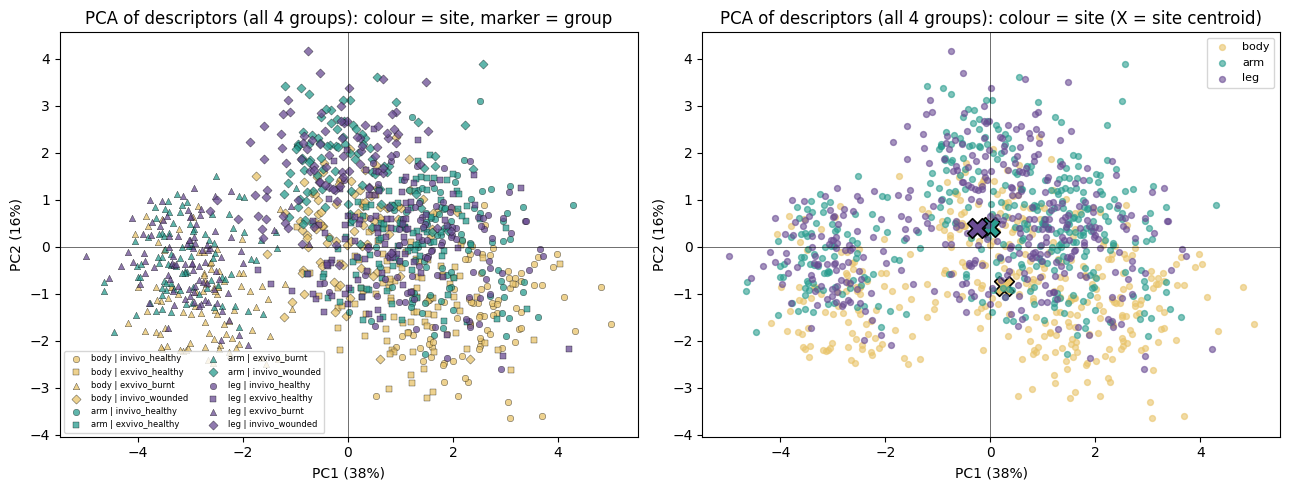

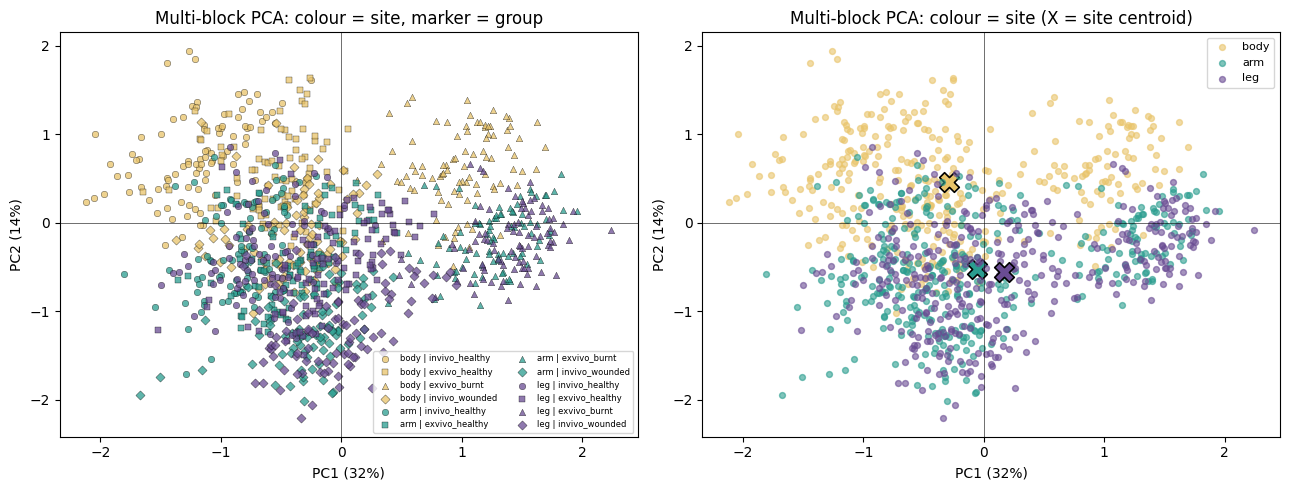

In [32]:
# PCA by site
SITE_COL = {"body": "#e9c46a", "arm": "#2a9d8f", "leg": "#6a4c93"}    
SITE_MK  = {"invivo_healthy": "o", "exvivo_healthy": "s", "exvivo_burnt": "^", "invivo_wounded": "D"}  # marker = group

pca_by_site(T_all, pca_all.explained_variance_ratio_, "PCA of descriptors (all 4 groups)", "fig12_pca_descriptors_by_site")
pca_by_site(Tmb,   pca_mb.explained_variance_ratio_,  "Multi-block PCA",                   "fig13_pca_multiblock_by_site")